# Module 1 — Climate damages: how does temperature affect economic growth?

**Project:** *Pricing the Future* — an empirical extension of my M.Sc. project (University of Bath) on discounting climate damages.

**Question.** The social cost of carbon (SCC) is the present value of the damages caused by one extra tonne of CO₂. Before we can *discount* damages (Modules 2–3), we need a credible estimate of *what the damages are*. Here we estimate how temperature affects GDP-per-capita growth.

**What the original paper did.** It regressed **world** GDP-per-capita growth on the **global** temperature anomaly. With one observation per year (~60 in total) the estimates were negative but not statistically significant.

**What this notebook does.**
1. Reproduces that global time-series approach as a baseline.
2. Re-estimates the relationship on a **panel of ~185 countries × ~60 years**, using within-country weather shocks for identification (Dell, Jones & Olken 2012; Burke, Hsiang & Miguel 2015).
3. Tests heterogeneity (rich vs poor) and robustness.
4. Exports the estimated damage function for the discounting engine in Module 2.

All computation lives in `R/07_damage_regressions.R`; this notebook runs it and explains the results.

In [1]:
# --- Setup -------------------------------------------------------------------
# The project scripts use paths relative to the repo root, so move there first.
if (basename(getwd()) == "notebooks") setwd("..")

# Bigger, sharper inline plots
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 120)

# Run the full Step 2 analysis. This estimates every model, writes the tables
# and figures to output/, and leaves all objects (models, figures) in memory.
source("R/07_damage_regressions.R")

[19:27:20] Estimation sample: 10216 obs, 185 countries


NOTE: 10 observations removed because of NA values (RHS: 10).

NOTE: 10 observations removed because of NA values (RHS: 10).

NOTE: 10 observations removed because of NA values (RHS: 10).

NOTE: 185 observations removed because of NA values (RHS: 185).



[19:27:21] Saved table1_global_timeseries.txt/.tex
[19:27:21] Saved table2_panel_main.txt/.tex
[19:27:21] Saved table3_robustness.txt/.tex
[19:27:22] Saved figures 1-3
[19:27:22] Saved damage_function_grid.csv  (161 rows x 10 cols)

================ STEP 2 KEY RESULTS ================
Main model: b_temp = 0.290, b_temp_sq = -0.0178 (N = 10216)
Growth-maximising temperature T* = 8.1°C  [95% CI -2.8, 19.0]
  +1°C effect at CAN (-4.1°C): +0.44 pp
  +1°C effect at USA (9.2°C): -0.04 pp
  +1°C effect at IND (24.0°C): -0.57 pp
  +1°C effect at NGA (26.9°C): -0.67 pp
Global time series, same-year anomaly coef: -2.038 (p = 0.260, N = 55)


## 1. The data

One row = one country-year. The dependent variable is GDP-per-capita growth, measured as 100 × the log-difference of real GDP per capita (≈ percentage points). Temperature is the annual mean 2 m air temperature from the Copernicus ERA5 reanalysis, averaged over each country's territory.

In [2]:
# Sample size and coverage
cat(sprintf("Observations: %s | Countries: %d | Years: %d-%d\n",
            format(nrow(est), big.mark = ","), n_distinct(est$iso3c),
            min(est$year), max(est$year)))

# Quick look at the two key variables
summary(est[, c("growth", "temp")])

Observations: 10,216 | Countries: 185 | Years: 1961-2025


     growth               temp       
 Min.   :-103.3487   Min.   :-20.70  
 1st Qu.:  -0.3846   1st Qu.: 12.15  
 Median :   2.0958   Median : 22.62  
 Mean   :   1.6905   Mean   : 19.04  
 3rd Qu.:   4.3757   3rd Qu.: 25.39  
 Max.   :  87.7511   Max.   : 29.79  

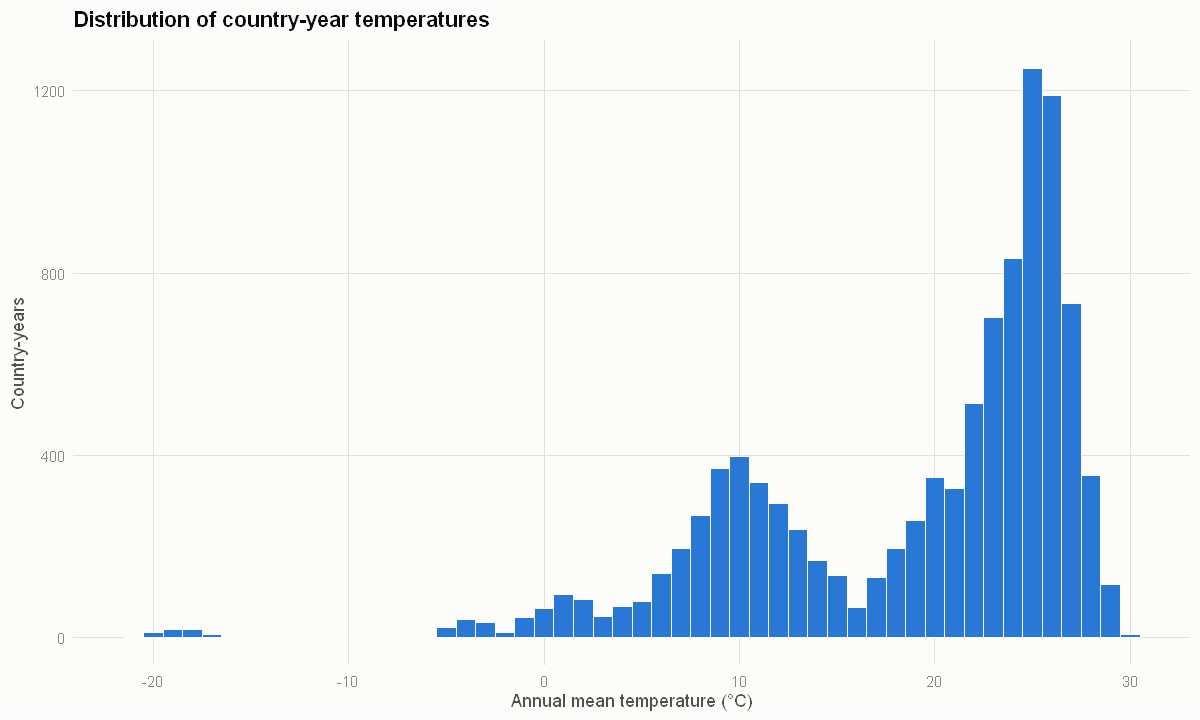

In [3]:
# Where do the observations sit on the temperature scale?
# This matters: the damage curve is only well-estimated where we have data.
ggplot(est, aes(temp)) +
  geom_histogram(binwidth = 1, fill = COL_MAIN, colour = "#fcfcfb", linewidth = 0.3) +
  labs(title = "Distribution of country-year temperatures",
       x = "Annual mean temperature (°C)", y = "Country-years") +
  theme_project()

## 2. Baseline: the original global time-series regression

$$\text{growth}^{W}_t = \alpha + \beta\,\text{Anomaly}_t + \gamma' X_t + \varepsilon_t$$

World growth is the population-weighted average across the panel's countries; the anomaly is NASA GISTEMP (vs 1951–80). Controls: world population growth and log global CO₂, as in the original paper. Standard errors are Newey–West (3 lags) because errors in an annual time series are autocorrelated.

**Why this design struggles.** There is one observation per year, and global temperature trends upward smoothly, so it is hard to separate the effect of warming from everything else that trended over the same decades (globalisation, China's rise, the slowdown in rich economies).

In [4]:
etable(m_ts, title = "Original approach: global time series")

,,Same-year,5-yr avg,Quadratic
,<chr>,<chr>,<chr>,<chr>
1,Dependent Var.:,World GDP pc growth (pp),World GDP pc growth (pp),World GDP pc growth (pp)
2,,,,
3,Constant,-20.59 (26.49),-28.17 (28.81),-4.559 (26.41)
4,Global temp. anomaly (°C),-2.038 (1.791),,1.966 (2.398)
5,World pop. growth (%),0.3269 (2.259),-0.8849 (2.299),-0.3645 (2.393)
6,log global CO2,2.428 (2.396),3.485 (2.755),0.8386 (2.361)
7,"Global anomaly, 5-yr avg",,-4.985 (3.169),
8,Global anomaly²,,,-2.892 (1.754)
9,_________________________,________________________,________________________,________________________


In [5]:
# Pull the headline number out programmatically so the text always matches the data
b_ts <- coef(m_ts[["Same-year"]])["anom"]; p_ts <- pvalue(m_ts[["Same-year"]])["anom"]
cat(sprintf("A 1°C higher global anomaly is associated with a %.2f pp change in world growth (p = %.2f, N = %d).\n",
            b_ts, p_ts, nobs(m_ts[["Same-year"]])))

A 1°C higher global anomaly is associated with a -2.04 pp change in world growth (p = 0.26, N = 55).


## 3. The panel approach: identifying the effect from weather shocks

$$\text{growth}_{it} = \beta_1 T_{it} + \beta_2 T_{it}^2 + \mu_i + \delta_t + \varepsilon_{it}$$

- **Country fixed effects $\mu_i$** absorb everything permanent about a country: geography, institutions, its *average* climate. We only use each country's deviations from its own normal.
- **Year fixed effects $\delta_t$** absorb shocks that hit every country in the same year: oil crises, 2008, COVID, and the *global* warming trend itself.
- What's left is: *"Was Canada unusually warm this year, relative to Canada's normal and relative to the rest of the world this year?"* Year-to-year weather is essentially random, so this is close to a natural experiment.
- **The quadratic term** lets the effect of +1°C depend on how hot a country already is:
  $$\frac{\partial\,\text{growth}}{\partial T} = \beta_1 + 2\beta_2 T, \qquad T^{*} = -\frac{\beta_1}{2\beta_2}$$
  If $\beta_2 < 0$, warming helps below $T^*$ and hurts above it.
- **Standard errors** are clustered by country (any correlation over time within a country). Column 4 uses Driscoll–Kraay errors, which also allow for correlation *across* countries in the same year, for example from a shared El Niño.

In [6]:
etable(m_panel, title = "Panel regressions")

,,Linear,Quadratic (main),+ country trends,Driscoll-Kraay SE
,<chr>,<chr>,<chr>,<chr>,<chr>
1,Dependent Var.:,GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp)
2,,,,,
3,Temperature (°C),-0.1208 (0.1813),0.2900 (0.2822),0.8541** (0.3180),0.2900 (0.5068)
4,Temperature²,,-0.0178* (0.0077),-0.0335*** (0.0091),-0.0178 (0.0142)
5,Fixed-Effects:,------------------,------------------,-------------------,------------------
6,Country,Yes,Yes,Yes,Yes
7,Year,Yes,Yes,Yes,Yes
8,Varying Slopes:,------------------,------------------,-------------------,------------------
9,Year (Country),No,No,Yes,No


In [7]:
cat(sprintf("Growth-maximising temperature T* = %.1f°C  (95%% CI %.1f to %.1f)\n\n",
            opt_main["t_opt"], opt_main["lo"], opt_main["hi"]))

# Effect of +1°C for selected countries at their sample-average temperature
labels_df |>
  transmute(Country = country, `Avg temp (°C)` = round(temp, 1),
            `Effect of +1°C on growth (pp)` = round(me, 2)) |>
  arrange(`Avg temp (°C)`)

Growth-maximising temperature T* = 8.1°C  (95% CI -2.8 to 19.0)



Country,Avg temp (°C),Effect of +1°C on growth (pp)
<chr>,<dbl>,<dbl>
Canada,-4.1,0.44
China,6.8,0.05
United States,9.2,-0.04
France,13.1,-0.18
India,24.0,-0.57
Brazil,24.7,-0.59
Nigeria,26.9,-0.67


### The damage function

The chart shows the *marginal* effect of a 1°C warmer year at each starting temperature. Above zero, warming raises growth; below zero, it lowers it. The shaded band is the 95% confidence interval. It widens at the extremes, where there are few observations (see the histogram above).

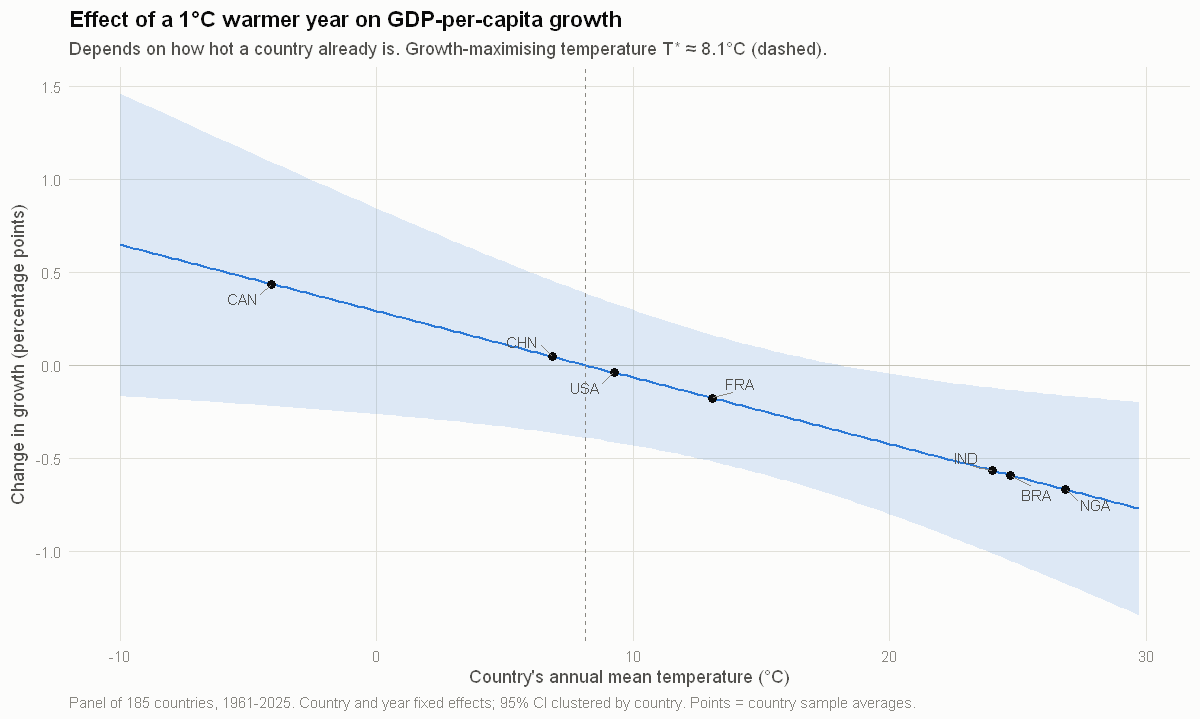

In [8]:
fig1

## 4. Heterogeneity: rich vs poor countries

A common finding is that poor countries are more exposed: more agriculture, less air-conditioning, weaker insurance. We split the sample at the median *initial* GDP per capita (initial, so that the split is not itself caused by later temperature shocks).

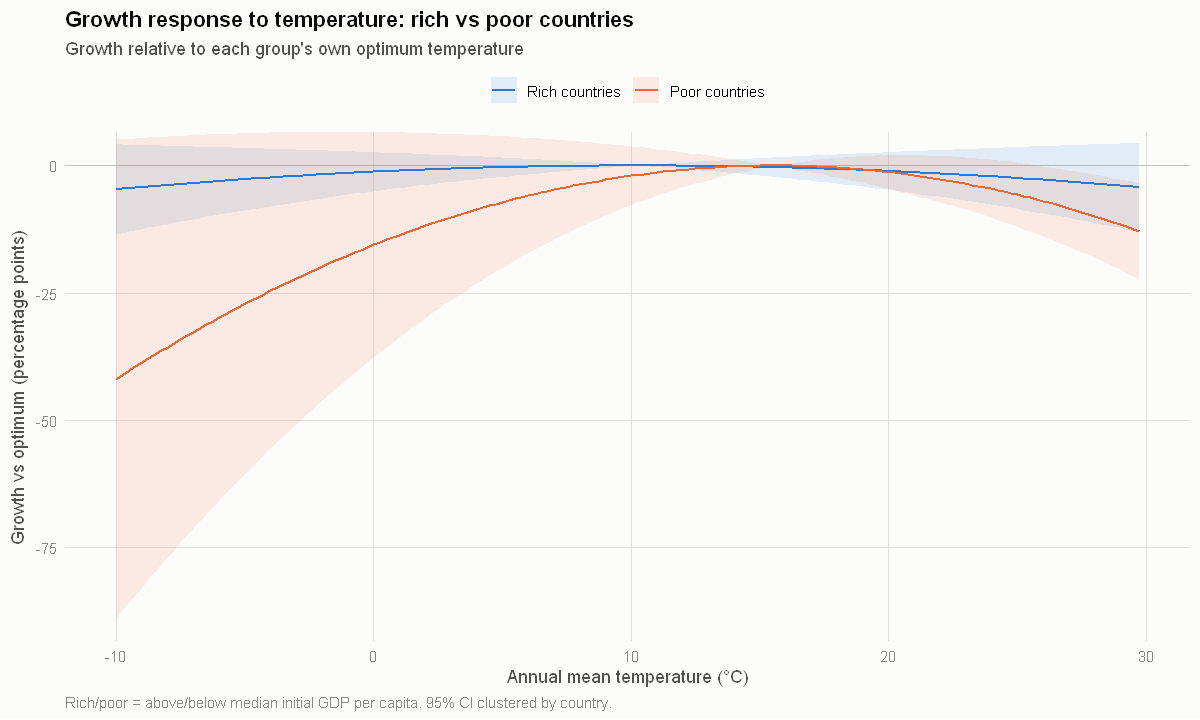

In [9]:
fig2

In [10]:
o_r <- optimum(m_rich); o_p <- optimum(m_poor)
cat(sprintf("Rich: T* = %.1f°C [%.1f, %.1f]  |  Poor: T* = %.1f°C [%.1f, %.1f]\n",
            o_r["t_opt"], o_r["lo"], o_r["hi"], o_p["t_opt"], o_p["lo"], o_p["hi"]))

Rich: T* = 10.3°C [-5.2, 25.8]  |  Poor: T* = 15.6°C [8.9, 22.2]


## 5. Robustness

| Check | Why |
|---|---|
| **Trim 1%** | Drops extreme growth years (wars, oil-state swings) that could drive the fit |
| **Population-weighted** | Gives large countries more weight, closer to "the average person" |
| **Post-1990** | Has the relationship changed as economies adapted? |
| **+ 1 lag** | If last year's heat matters with the *opposite* sign, the effect is a temporary dip in levels that recovers; if not, it's a persistent growth effect, which compounds into much larger long-run damages |
| **Anomaly (linear)** | The original paper's anomaly concept, now computed country by country |
| **+ country trends** (Table 2) | Lets each country have its own growth trend |

In [11]:
etable(c(m_robust, list("Rich" = m_rich, "Poor" = m_poor)), title = "Robustness and heterogeneity")

,,Main,Trim 1%,Pop.-weighted,Post-1990,+ 1 lag,Anomaly (linear),Rich,Poor
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Sample (Poor),,,,,,,0,1
2,Dependent Var.:,GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp),GDP pc growth (pp)
3,,,,,,,,,
4,Temperature (°C),0.2900 (0.2822),-0.0578 (0.1621),-0.2595 (0.5996),1.344** (0.5031),0.4165 (0.2751),,0.2326 (0.2224),1.994. (1.060)
5,Temperature²,-0.0178* (0.0077),-0.0044 (0.0049),-0.0165 (0.0132),-0.0453** (0.0145),-0.0231** (0.0080),,-0.0113 (0.0069),-0.0640** (0.0234)
6,"l(temp, 1)",,,,,-0.4921* (0.2094),,,
7,"l(temp_sq, 1)",,,,,0.0086 (0.0075),,,
8,Temp. anomaly vs 1951-80 (°C),,,,,,-0.1208 (0.1813),,
9,Fixed-Effects:,------------------,------------------,------------------,------------------,------------------,------------------,------------------,------------------


In [12]:
# Lag model: the cumulative effect = contemporaneous + lagged coefficients.
# If the lag simply reversed the shock, the cumulative effect would be ~0.
b_l <- coef(m_lag)
cat(sprintf("Contemporaneous: b1 = %.3f, b2 = %.4f\nLagged:          b1 = %.3f, b2 = %.4f\n",
            b_l["temp"], b_l["temp_sq"], b_l["l(temp, 1)"], b_l["l(temp_sq, 1)"]))

Contemporaneous: b1 = 0.417, b2 = -0.0231
Lagged:          b1 = -0.492, b2 = 0.0086


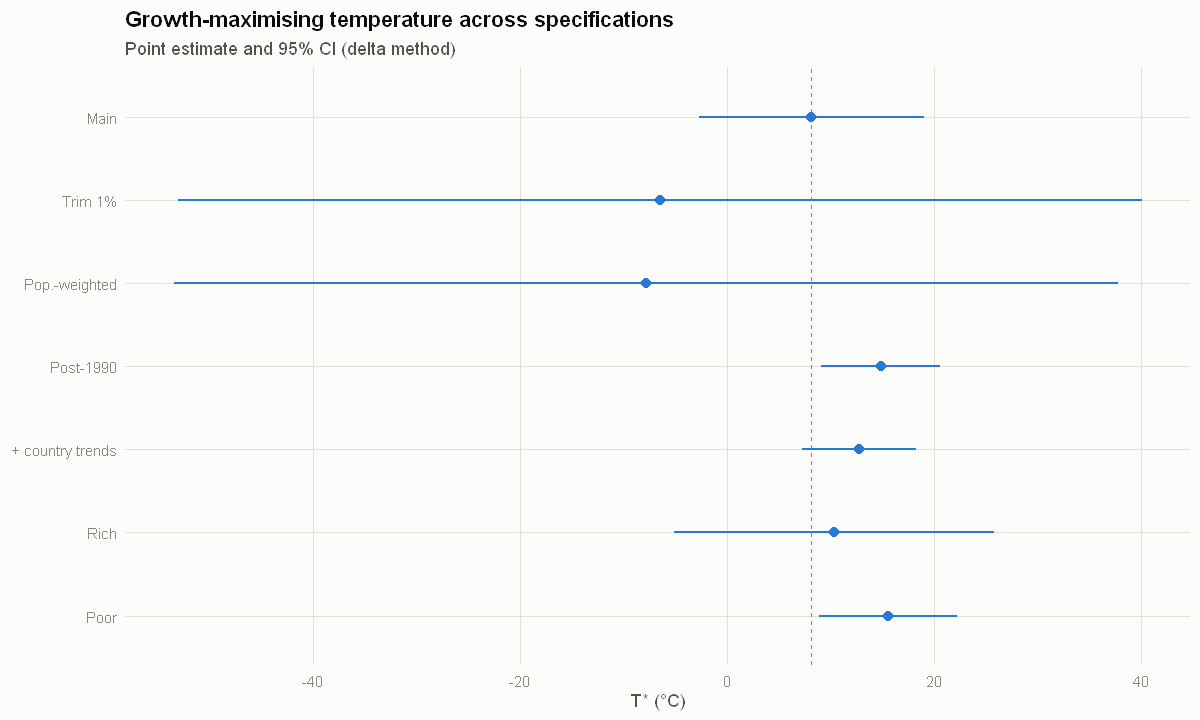

In [13]:
fig3

## 6. Takeaways and hand-off to Module 2

- Use the printed results above to fill in this section once the final data run is in. Things to report: the sign and significance of $\beta_2$, the location of $T^*$, how the panel compares with the global time series, and whether poor countries are more exposed.
- **Canada** sits at the cold end of the distribution, so in this framework moderate warming is estimated to have small or even positive direct growth effects. The SCC is a *global* damage measure, though, and most of the world's population and output sit at or above $T^*$.
- **Caveats:** these are short-run responses to weather. Long-run climate change allows adaptation (which lowers damages) but also brings sea-level rise, tipping points and extreme events not captured by annual mean temperature (which raise damages). The original paper's discussion of the dismal theorem and catastrophic tails speaks directly to this gap.

**Output for Module 2:** `output/tables/damage_coefficients.json` stores $\beta_1$, $\beta_2$, their covariance matrix, and the rich/poor variants. The Python discounting engine will use these to build damage streams under warming scenarios, then value them under fixed, Weitzman, Newell–Pizer and SDF discounting.

In [14]:
# Confirm what was exported for Module 2
str(jsonlite::fromJSON("output/tables/damage_coefficients.json"), max.level = 2)

List of 7
 $ description     : chr "Panel damage function: growth_it = b_temp*T + b_temp_sq*T^2 + country FE + year FE. Growth in percentage points"| __truncated__
 $ sample          :List of 2
  ..$ countries: int 185
  ..$ years    : int [1:2] 1961 2025
 $ main            :List of 6
  ..$ b_temp   : num 0.29
  ..$ b_temp_sq: num -0.0178
  ..$ vcov     : num [1:2, 1:2] 7.96e-02 -1.73e-03 -1.73e-03 5.96e-05
  ..$ t_opt    : num 8.13
  ..$ t_opt_se : num 5.55
  ..$ n_obs    : int 10216
 $ rich            :List of 6
  ..$ b_temp   : num 0.233
  ..$ b_temp_sq: num -0.0113
  ..$ vcov     : num [1:2, 1:2] 0.049475 -0.000925 -0.000925 0.000048
  ..$ t_opt    : num 10.3
  ..$ t_opt_se : num 7.91
  ..$ n_obs    : int 4920
 $ poor            :List of 6
  ..$ b_temp   : num 1.99
  ..$ b_temp_sq: num -0.064
  ..$ vcov     : num [1:2, 1:2] 1.122857 -0.023502 -0.023502 0.000547
  ..$ t_opt    : num 15.6
  ..$ t_opt_se : num 3.4
  ..$ n_obs    : int 5296
 $ canada_mean_temp: num -4.1
 $ created     